Subscription churn prediction

Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Load the data

viewing the data

In [2]:
df=pd.read_csv("Subscription_Service_Churn_Dataset.csv")

In [3]:
print(df.head())

   AccountAge  MonthlyCharges  TotalCharges SubscriptionType  \
0          42       11.321950    475.521914            Basic   
1          95       12.810915   1217.036887         Standard   
2           6             NaN     91.583304         Standard   
3          54       17.917819    967.562224            Basic   
4          27             NaN    339.057244            Basic   

      PaymentMethod PaperlessBilling ContentType MultiDeviceAccess  \
0  Electronic check              Yes      Movies               Yes   
1  Electronic check              Yes    TV Shows                No   
2       Credit card              Yes    TV Shows                No   
3               NaN              Yes      Movies                No   
4      Mailed check               No    TV Shows                No   

  DeviceRegistered  ViewingHoursPerWeek  ...  ContentDownloadsPerMonth  \
0           Tablet             0.386852  ...                        25   
1           Mobile            37.123000  ...  

In [4]:
print(df.columns)

Index(['AccountAge', 'MonthlyCharges', 'TotalCharges', 'SubscriptionType',
       'PaymentMethod', 'PaperlessBilling', 'ContentType', 'MultiDeviceAccess',
       'DeviceRegistered', 'ViewingHoursPerWeek', 'AverageViewingDuration',
       'ContentDownloadsPerMonth', 'GenrePreference', 'UserRating',
       'SupportTicketsPerMonth', 'Gender', 'WatchlistSize', 'ParentalControl',
       'SubtitlesEnabled', 'CustomerID', 'Churn'],
      dtype='object')


In [5]:
print(df.shape)

(963, 21)


In [6]:
print(df.dtypes)

AccountAge                    int64
MonthlyCharges              float64
TotalCharges                float64
SubscriptionType             object
PaymentMethod                object
PaperlessBilling             object
ContentType                  object
MultiDeviceAccess            object
DeviceRegistered             object
ViewingHoursPerWeek         float64
AverageViewingDuration      float64
ContentDownloadsPerMonth      int64
GenrePreference              object
UserRating                  float64
SupportTicketsPerMonth        int64
Gender                       object
WatchlistSize                 int64
ParentalControl              object
SubtitlesEnabled             object
CustomerID                   object
Churn                         int64
dtype: object


In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 963 entries, 0 to 962
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   AccountAge                963 non-null    int64  
 1   MonthlyCharges            759 non-null    float64
 2   TotalCharges              777 non-null    float64
 3   SubscriptionType          913 non-null    object 
 4   PaymentMethod             740 non-null    object 
 5   PaperlessBilling          963 non-null    object 
 6   ContentType               963 non-null    object 
 7   MultiDeviceAccess         963 non-null    object 
 8   DeviceRegistered          887 non-null    object 
 9   ViewingHoursPerWeek       963 non-null    float64
 10  AverageViewingDuration    963 non-null    float64
 11  ContentDownloadsPerMonth  963 non-null    int64  
 12  GenrePreference           853 non-null    object 
 13  UserRating                702 non-null    float64
 14  SupportTic

In [8]:
df.describe()

,AccountAge,MonthlyCharges,TotalCharges,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,UserRating,SupportTicketsPerMonth,WatchlistSize,Churn
count,963.000000,759.000000,777.000000,963.000000,963.000000,963.000000,702.000000,963.000000,963.000000,963.000000
mean,57.515057,12.328262,714.052121,21.029241,90.741877,24.694704,2.923945,4.455867,11.900312,0.175493
std,33.662575,4.260861,511.071322,11.318164,49.923719,14.319572,1.165992,2.935706,7.117402,0.380586
min,1.000000,5.062339,11.582882,0.315317,5.028412,0.000000,1.000181,0.000000,0.000000,0.000000
25%,29.000000,8.816669,318.425396,11.621961,47.777701,13.000000,1.922235,2.000000,6.000000,0.000000
50%,55.000000,12.169888,614.196606,21.334100,89.878241,25.000000,2.898328,5.000000,12.000000,0.000000
75%,86.000000,15.937606,1021.436452,30.419851,134.353824,37.000000,3.953953,7.000000,18.000000,0.000000
max,119.000000,19.932542,2261.019201,39.949086,179.752024,49.000000,4.997348,9.000000,24.000000,1.000000


In [9]:
df.isnull()

,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,CustomerID,Churn
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,True,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
3,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
959,False,False,False,False,True,False,False,False,False,False,...,False,True,True,False,False,False,False,True,False,False
960,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
961,False,False,True,False,True,False,False,False,False,False,...,False,False,True,False,False,False,False,True,False,False


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isna().sum().sum()

np.int64(1950)

In [12]:
df[df['MonthlyCharges'].isna()]

,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,CustomerID,Churn
2,6,NaN,91.583304,Standard,Credit card,Yes,TV Shows,No,Tablet,30.716944,...,29,Fantasy,NaN,4,Male,14,No,Yes,JB5J8X2UY1,1
4,27,NaN,339.057244,Basic,Mailed check,No,TV Shows,No,Mobile,39.936910,...,44,Comedy,3.236230,4,Female,18,No,NaN,B3BDJTW0L9,0
5,71,NaN,818.287054,Premium,Credit card,No,Movies,Yes,Computer,7.310172,...,30,Comedy,2.779614,6,Female,16,Yes,NaN,5E4TQK5OVX,0
8,8,NaN,NaN,Premium,Electronic check,No,Both,Yes,Computer,15.488913,...,16,Fantasy,NaN,3,Female,2,No,Yes,IGZ39O1ROC,0
10,102,NaN,1954.784656,Premium,NaN,No,Movies,Yes,Mobile,38.919239,...,29,NaN,2.683853,6,Male,19,Yes,Yes,W636FZ4VNV,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
945,39,NaN,364.320544,Basic,Credit card,No,Both,Yes,Computer,11.299914,...,29,Drama,1.378773,6,Female,14,Yes,NaN,074PZ3GZSG,0
948,63,NaN,915.751142,Premium,Credit card,Yes,TV Shows,Yes,Mobile,12.312192,...,29,NaN,2.126789,2,Male,17,No,NaN,XW3KL8GLF1,0
950,30,NaN,NaN,Standard,NaN,No,TV Shows,Yes,Mobile,21.738853,...,9,Action,4.227247,7,Male,11,Yes,NaN,ZZ2AOBLX7L,1
952,22,NaN,NaN,Standard,Electronic check,No,TV Shows,Yes,Mobile,28.158003,...,4,Sci-Fi,1.437629,7,Male,24,No,NaN,GEF3YMDT2A,0


In [13]:
df.dropna(axis=1)

,AccountAge,PaperlessBilling,ContentType,MultiDeviceAccess,ViewingHoursPerWeek,AverageViewingDuration,ContentDownloadsPerMonth,SupportTicketsPerMonth,WatchlistSize,ParentalControl,CustomerID,Churn
0,42,Yes,Movies,Yes,0.386852,24.593361,25,7,15,No,LOHRYYC9E8,0
1,95,Yes,TV Shows,No,37.123000,102.860795,21,3,8,No,RIH7RFEZCS,0
2,6,Yes,TV Shows,No,30.716944,10.512415,29,4,14,No,JB5J8X2UY1,1
3,54,Yes,Movies,No,2.495373,45.246834,45,3,12,No,Z4GZJIB90P,0
4,27,No,TV Shows,No,39.936910,94.310954,44,4,18,No,B3BDJTW0L9,0
...,...,...,...,...,...,...,...,...,...,...,...,...
958,83,No,Movies,No,2.520628,45.949435,40,9,21,Yes,AV3ZDGUB4C,0
959,67,Yes,TV Shows,No,3.737329,25.272097,40,1,22,No,15GWB8NVG5,0
960,119,Yes,TV Shows,Yes,5.691826,38.849305,5,2,23,No,6VUYH24HVW,0
961,57,Yes,Movies,No,30.267865,125.147142,40,0,14,No,X1OE7MMFDL,0


In [14]:
df['MonthlyCharges']=df['MonthlyCharges'].fillna(df['MonthlyCharges'].mean())

In [15]:
df['TotalCharges']=df['TotalCharges'].fillna(df['TotalCharges'].mean())


In [16]:
df['ViewingHoursPerWeek']=df['ViewingHoursPerWeek'].fillna(df['ViewingHoursPerWeek'].mean())

In [17]:
df['UserRating']=df['UserRating'].fillna(df['UserRating'].mean())


In [18]:
df['SubscriptionType']=df['SubscriptionType'].fillna(df['SubscriptionType'].mode()[0])

In [19]:
df['PaymentMethod']=df['PaymentMethod'].fillna(df['PaymentMethod'].mode()[0])

In [20]:
df['DeviceRegistered']=df['DeviceRegistered'].fillna(df['DeviceRegistered'].mode()[0])

In [21]:
df['GenrePreference']=df['GenrePreference'].fillna(df['GenrePreference'].mode()[0])

In [22]:
df['Gender']=df['Gender'].fillna(df['Gender'].mode()[0])

In [23]:
df['SubtitlesEnabled']=df['SubtitlesEnabled'].fillna(df['SubtitlesEnabled'].mode()[0])

In [24]:
df['CustomerID']=df['CustomerID'].fillna(df['CustomerID'].mode()[0])

In [25]:
df.drop("CustomerID", axis=1, inplace=True)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 963 entries, 0 to 962
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   AccountAge                963 non-null    int64  
 1   MonthlyCharges            963 non-null    float64
 2   TotalCharges              963 non-null    float64
 3   SubscriptionType          963 non-null    object 
 4   PaymentMethod             963 non-null    object 
 5   PaperlessBilling          963 non-null    object 
 6   ContentType               963 non-null    object 
 7   MultiDeviceAccess         963 non-null    object 
 8   DeviceRegistered          963 non-null    object 
 9   ViewingHoursPerWeek       963 non-null    float64
 10  AverageViewingDuration    963 non-null    float64
 11  ContentDownloadsPerMonth  963 non-null    int64  
 12  GenrePreference           963 non-null    object 
 13  UserRating                963 non-null    float64
 14  SupportTic

In [27]:
df.to_csv("Subscription_Service_Churn_Cleaned_Dataset.csv", index=False)

Outlier detection

Box plot

In [28]:
# Exclude target variable
outlier_cols = df.select_dtypes(include=np.number).columns.drop("Churn")

print("Columns used for outlier detection:")
print(list(outlier_cols))

Columns used for outlier detection:
['AccountAge', 'MonthlyCharges', 'TotalCharges', 'ViewingHoursPerWeek', 'AverageViewingDuration', 'ContentDownloadsPerMonth', 'UserRating', 'SupportTicketsPerMonth', 'WatchlistSize']


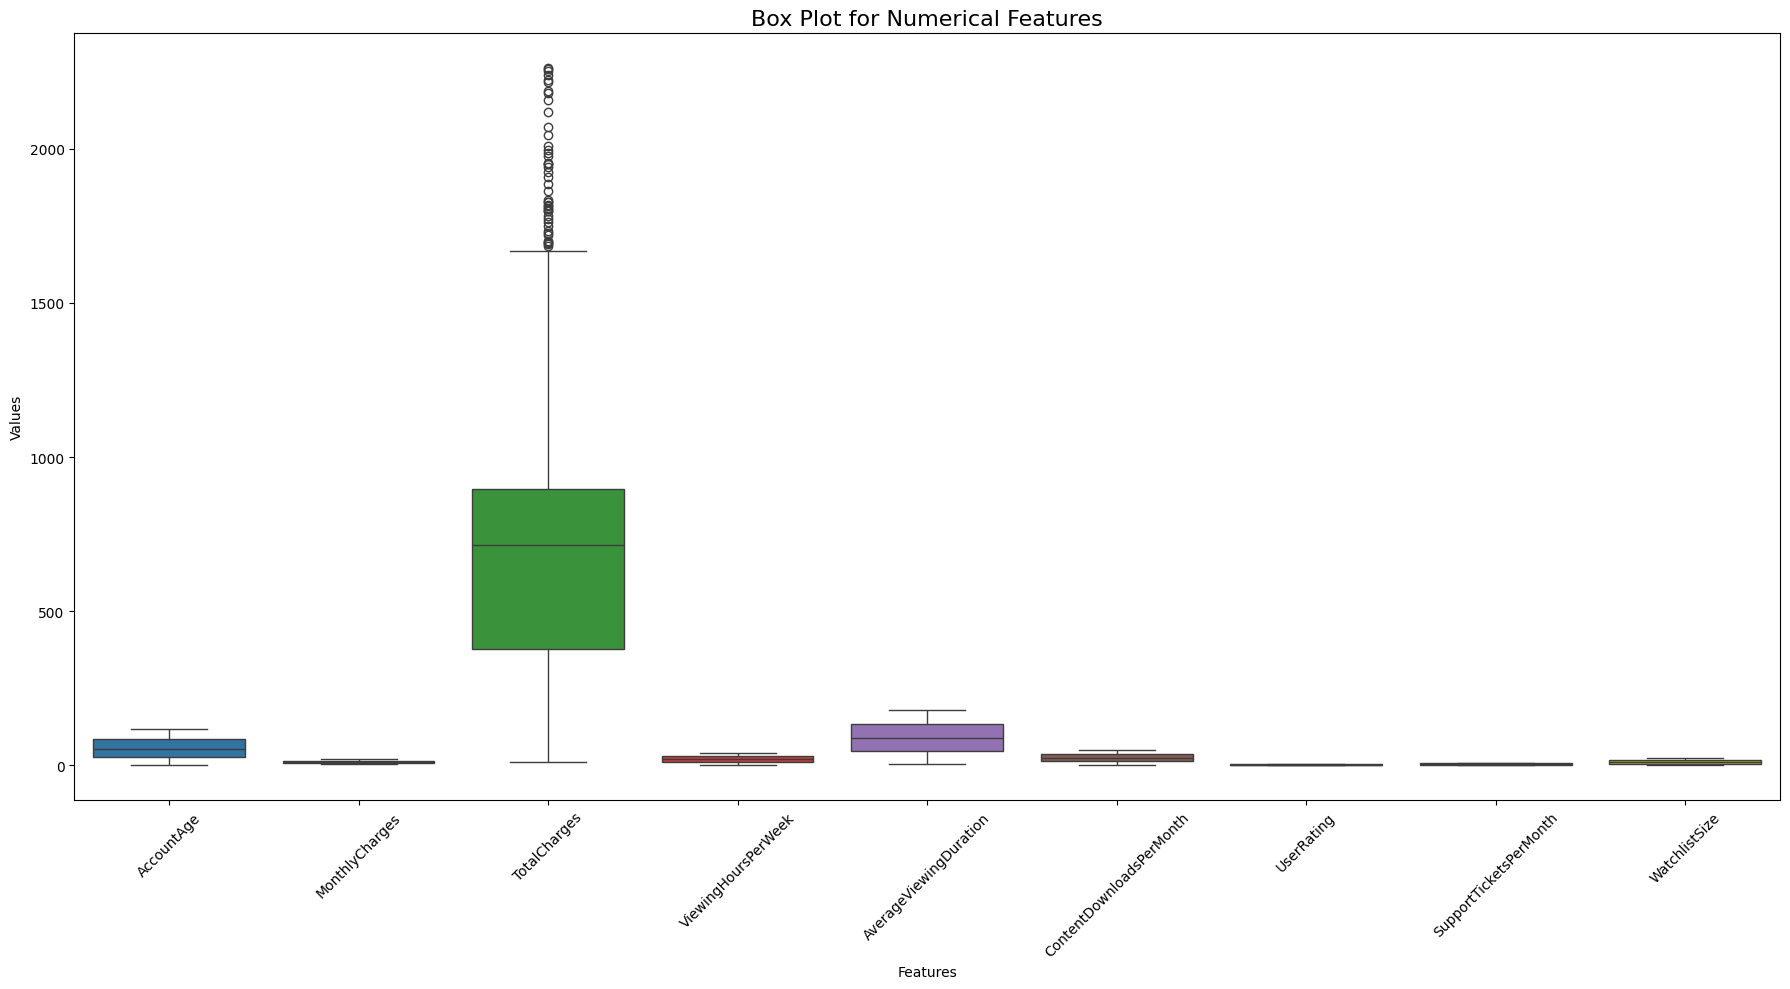

In [29]:
plt.figure(figsize=(18, 10))

sns.boxplot(data=df[outlier_cols])

plt.title("Box Plot for Numerical Features", fontsize=16)
plt.xlabel("Features")
plt.ylabel("Values")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
# IQR Outlier Detection

iqr_results = []

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    iqr_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (len(outliers) / len(df)) * 100
    })

iqr_summary = pd.DataFrame(iqr_results)

display(iqr_summary)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,AccountAge,29.000000,86.000000,57.000000,-56.500000,171.500000,0,0.000000
1,MonthlyCharges,9.576123,15.012909,5.436786,1.420944,23.168088,0,0.000000
2,TotalCharges,377.052449,895.658870,518.606421,-400.857183,1673.568502,45,4.672897
3,ViewingHoursPerWeek,11.621961,30.419851,18.797890,-16.574873,58.616685,0,0.000000
4,AverageViewingDuration,47.777701,134.353824,86.576123,-82.086483,264.218008,0,0.000000
5,ContentDownloadsPerMonth,13.000000,37.000000,24.000000,-23.000000,73.000000,0,0.000000
6,UserRating,2.275808,3.522727,1.246920,0.405428,5.393107,0,0.000000
7,SupportTicketsPerMonth,2.000000,7.000000,5.000000,-5.500000,14.500000,0,0.000000
8,WatchlistSize,6.000000,18.000000,12.000000,-12.000000,36.000000,0,0.000000


In [31]:
iqr_outliers_only = iqr_summary[iqr_summary["Outlier Count"] > 0]

print("Features containing IQR outliers:")
display(iqr_outliers_only)

Features containing IQR outliers:


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
2,TotalCharges,377.052449,895.65887,518.606421,-400.857183,1673.568502,45,4.672897


Outlier detection

Z score

In [32]:
from scipy.stats import zscore
# Calculate Z-scores
z_scores = df[outlier_cols].apply(zscore)

# Identify outliers
z_outlier_mask = z_scores.abs() > 3

# Count outliers in each column
z_outlier_count = z_outlier_mask.sum()

z_summary = pd.DataFrame({
    "Feature": outlier_cols,
    "Outlier Count": z_outlier_count.values,
    "Outlier Percentage":
        (z_outlier_count.values / len(df)) * 100
})

display(z_summary)

,Feature,Outlier Count,Outlier Percentage
0,AccountAge,0,0.000000
1,MonthlyCharges,0,0.000000
2,TotalCharges,10,1.038422
3,ViewingHoursPerWeek,0,0.000000
4,AverageViewingDuration,0,0.000000
5,ContentDownloadsPerMonth,0,0.000000
6,UserRating,0,0.000000
7,SupportTicketsPerMonth,0,0.000000
8,WatchlistSize,0,0.000000


In [33]:
z_outliers_only = z_summary[z_summary["Outlier Count"] > 0]

print("Features containing Z-score outliers:")
display(z_outliers_only)

Features containing Z-score outliers:


,Feature,Outlier Count,Outlier Percentage
2,TotalCharges,10,1.038422


Week 4:EDA DEEP DRIVE.Univariate and Bivariate analysis.Visualizing distributions.

**Account Age:**

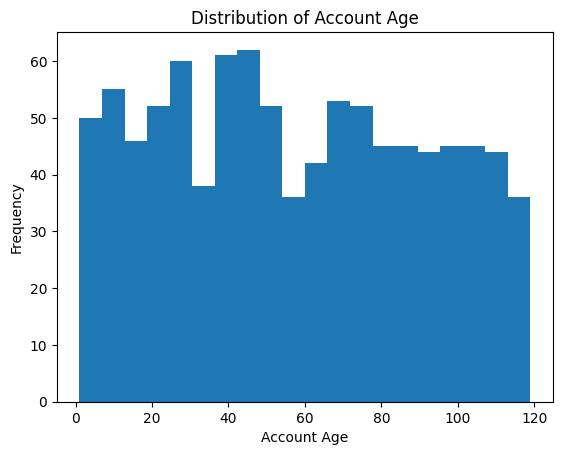

In [34]:
df1 = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.hist(df1["AccountAge"], bins=20)
plt.xlabel("Account Age")
plt.ylabel("Frequency")
plt.title("Distribution of Account Age")
plt.show()

**Distribution of Monthly Charges:**

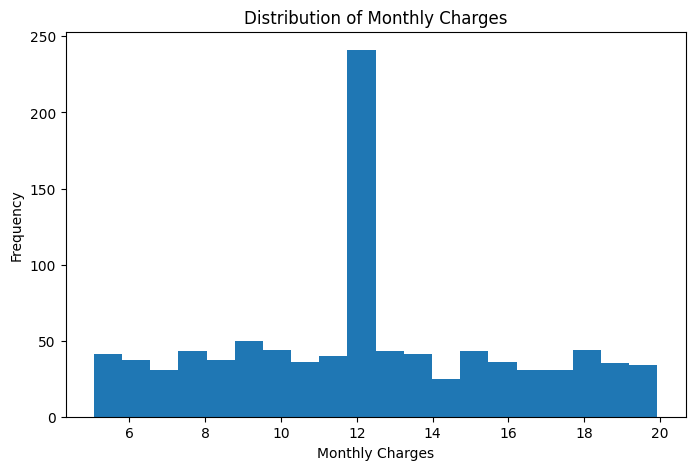

In [35]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.hist(df["MonthlyCharges"], bins=20)
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")
plt.title("Distribution of Monthly Charges")
plt.show()

**User Rating:**

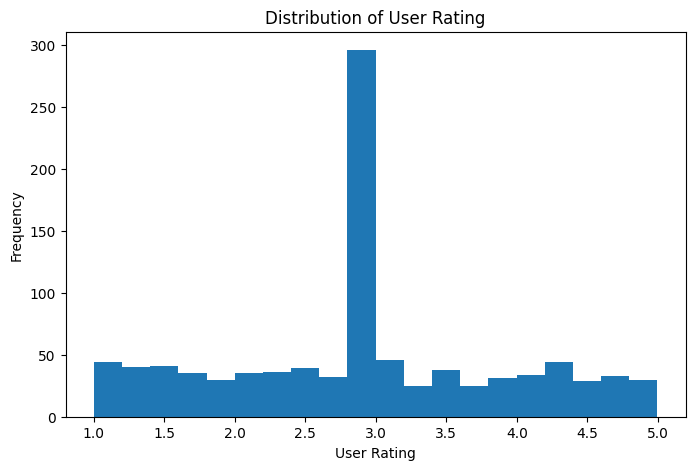

In [36]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.hist(df["UserRating"], bins=20)
plt.xlabel("User Rating")
plt.ylabel("Frequency")
plt.title("Distribution of User Rating")
plt.show()

**Average Viewing Duration:**

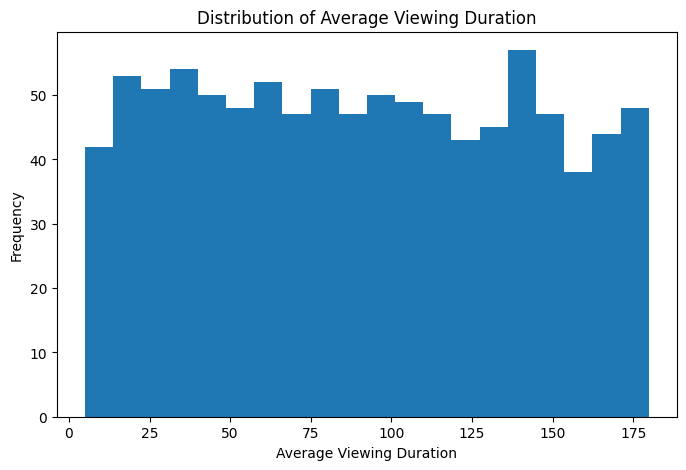

In [37]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.hist(df["AverageViewingDuration"], bins=20)
plt.xlabel("Average Viewing Duration")
plt.ylabel("Frequency")
plt.title("Distribution of Average Viewing Duration")
plt.show()

**Subscription Type:**

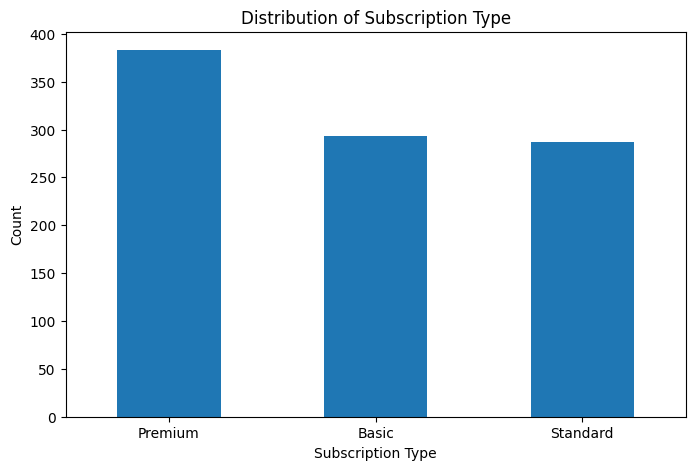

In [38]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["SubscriptionType"].value_counts().plot(kind="bar")
plt.xlabel("Subscription Type")
plt.ylabel("Count")
plt.title("Distribution of Subscription Type")
plt.xticks(rotation=0)
plt.show()

**Payment Method:**

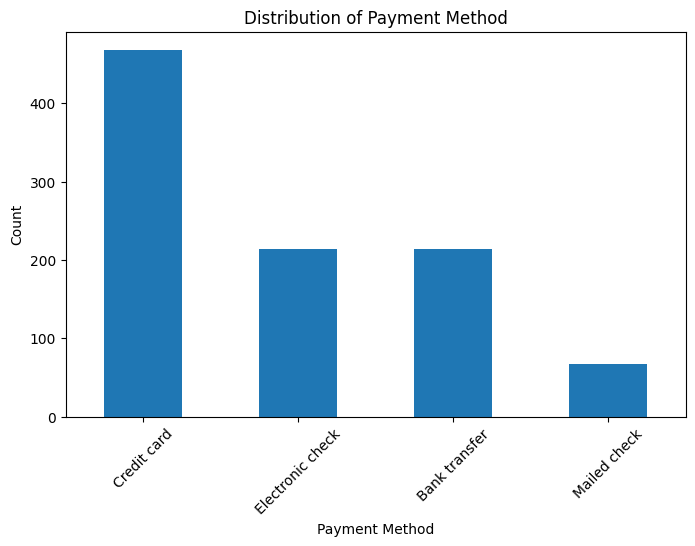

In [39]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["PaymentMethod"].value_counts().plot(kind="bar")
plt.xlabel("Payment Method")
plt.ylabel("Count")
plt.title("Distribution of Payment Method")
plt.xticks(rotation=45)
plt.show()

**Genre Preference:**

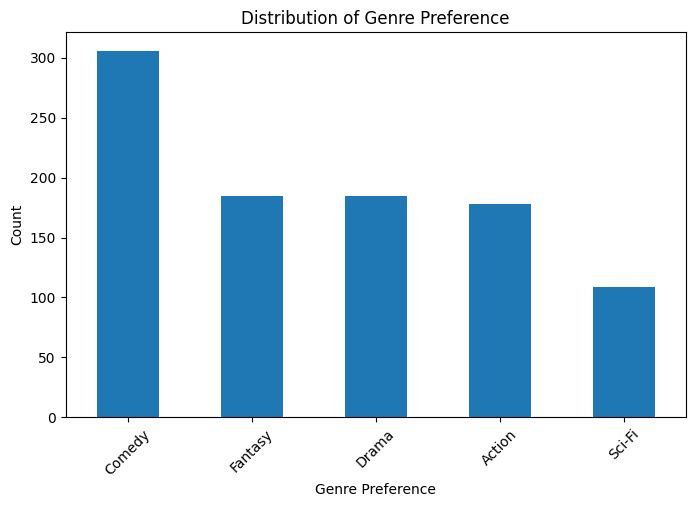

In [40]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["GenrePreference"].value_counts().plot(kind="bar")
plt.xlabel("Genre Preference")
plt.ylabel("Count")
plt.title("Distribution of Genre Preference")
plt.xticks(rotation=45)
plt.show()

**Gender:**

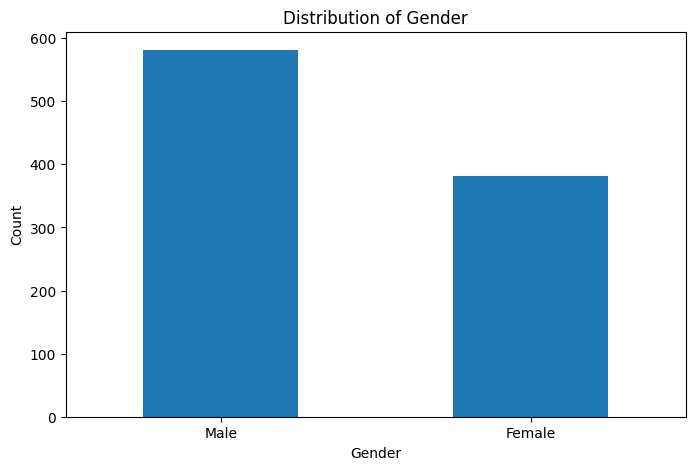

In [41]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["Gender"].value_counts().plot(kind="bar")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Distribution of Gender")
plt.xticks(rotation=0)
plt.show()

**SubtitlesEnabled:**

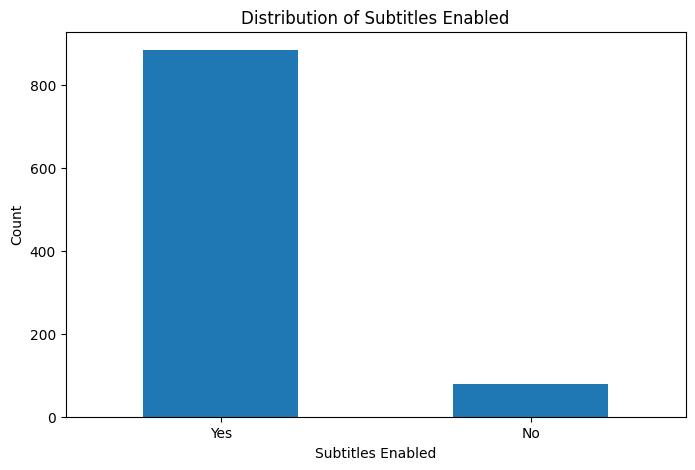

In [42]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
df["SubtitlesEnabled"].value_counts().plot(kind="bar")
plt.xlabel("Subtitles Enabled")
plt.ylabel("Count")
plt.title("Distribution of Subtitles Enabled")
plt.xticks(rotation=0)
plt.show()

**Churn:**

**Bivariate Analysis:**

**Bar Plot — SubscriptionType vs Churn:**

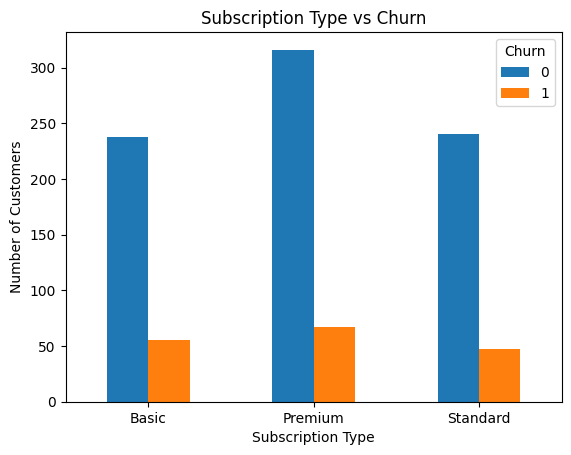

In [47]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

pd.crosstab(df["SubscriptionType"], df["Churn"]).plot(kind="bar")

plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")
plt.title("Subscription Type vs Churn")
plt.xticks(rotation=0)
plt.show()

**PaymentMethod vs Churn:**

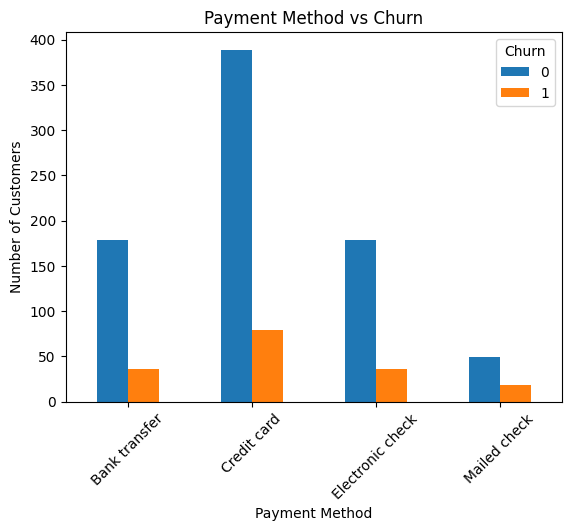

In [48]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

pd.crosstab(df["PaymentMethod"], df["Churn"]).plot(kind="bar")

plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.title("Payment Method vs Churn")
plt.xticks(rotation=45)
plt.show()

**SubscriptionType vs PaymentMethod:**

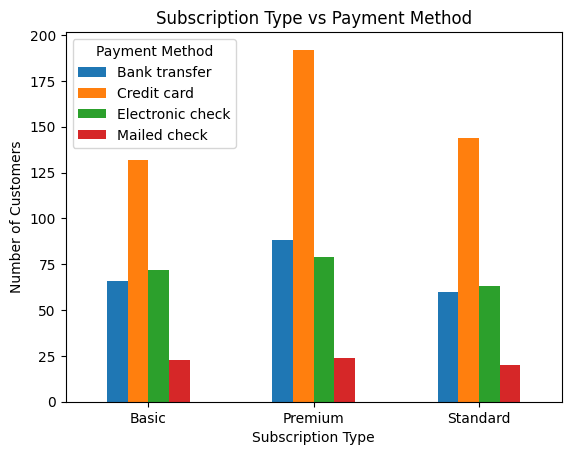

In [50]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

pd.crosstab(df["SubscriptionType"], df["PaymentMethod"]).plot(kind="bar")

plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")
plt.title("Subscription Type vs Payment Method")
plt.xticks(rotation=0)
plt.legend(title="Payment Method")
plt.show()

**DeviceRegistered vs MultiDeviceAccess:**

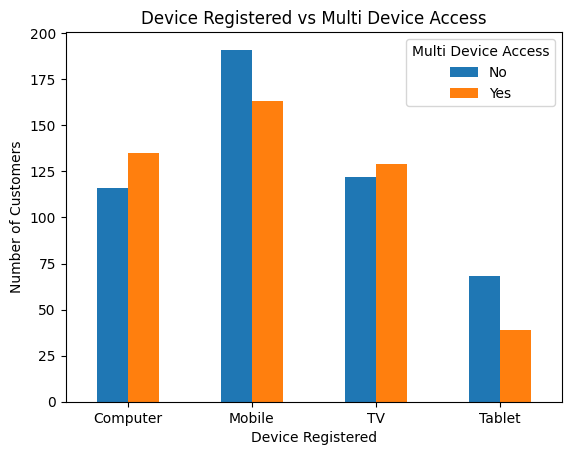

In [51]:

df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

pd.crosstab(df["DeviceRegistered"], df["MultiDeviceAccess"]).plot(kind="bar")

plt.xlabel("Device Registered")
plt.ylabel("Number of Customers")
plt.title("Device Registered vs Multi Device Access")
plt.xticks(rotation=0)
plt.legend(title="Multi Device Access")
plt.show()

**Account Age vs Total Charges:**

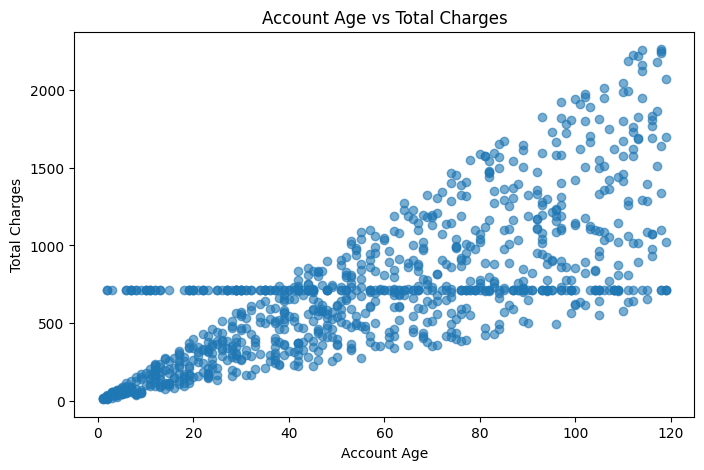

In [53]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.scatter(df["AccountAge"], df["TotalCharges"], alpha=0.6)

plt.xlabel("Account Age")
plt.ylabel("Total Charges")
plt.title("Account Age vs Total Charges")
plt.show()

**MonthlyCharges vs TotalCharges:**

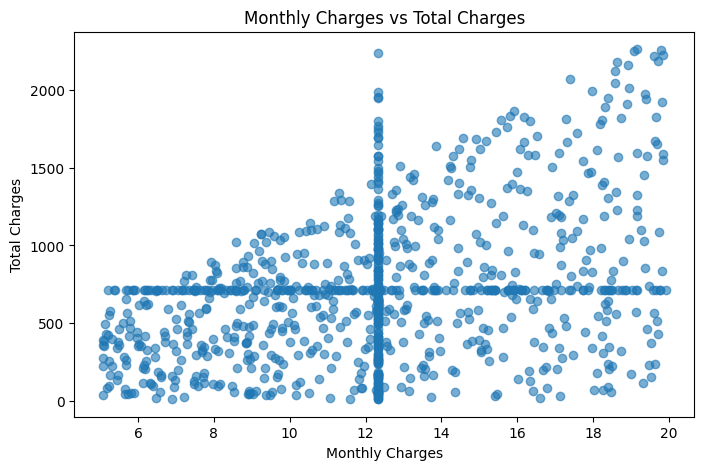

In [55]:


df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

plt.figure(figsize=(8,5))
plt.scatter(df["MonthlyCharges"], df["TotalCharges"], alpha=0.6)

plt.xlabel("Monthly Charges")
plt.ylabel("Total Charges")
plt.title("Monthly Charges vs Total Charges")
plt.show()

**Content Type vs Viewing Hours:**

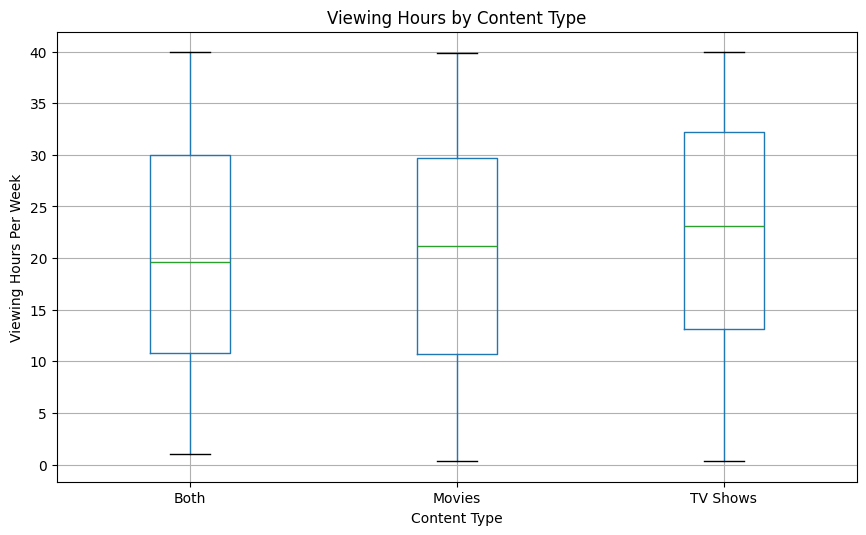

In [59]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

df.boxplot(column="ViewingHoursPerWeek", by="ContentType", figsize=(10,6))

plt.xlabel("Content Type")
plt.ylabel("Viewing Hours Per Week")
plt.title("Viewing Hours by Content Type")
plt.suptitle("")
plt.show()

**Gender vs User Rating:**

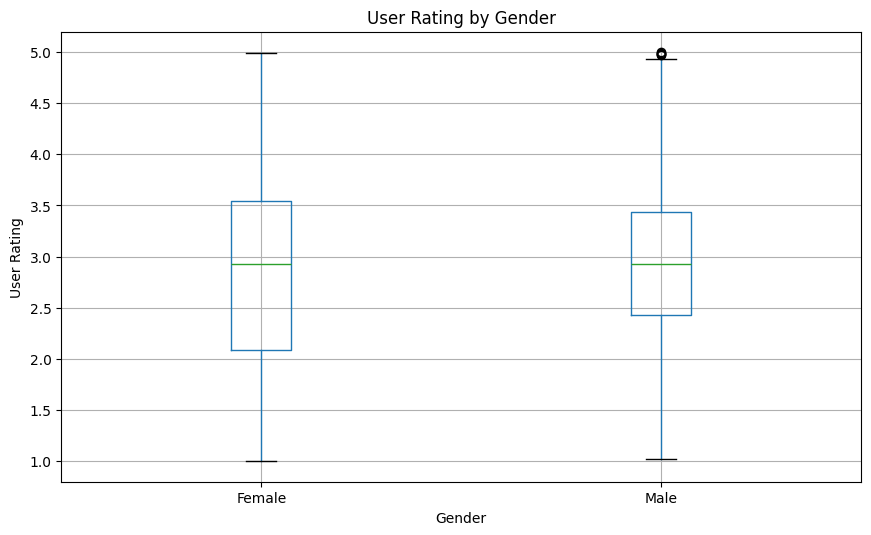

In [60]:
df = pd.read_csv("Subscription_Service_Churn_Cleaned_Dataset.csv")

df.boxplot(column="UserRating", by="Gender", figsize=(10,6))

plt.xlabel("Gender")
plt.ylabel("User Rating")
plt.title("User Rating by Gender")
plt.suptitle("")
plt.show()